In [1]:
import os
import json
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

Paths and settings

In [4]:
DATA_PATH = "../dataset/modis_dataset/modis_2020_Turkey.csv"

MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")
PROCESSED_DIR = Path("../dataset/processed")

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

Count images

In [6]:
df = pd.read_csv(DATA_PATH)

df.head()
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (8834, 15)

Columns:
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']


Cell 4 — Dataset information

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8834 entries, 0 to 8833
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   latitude    8834 non-null   float64
 1   longitude   8834 non-null   float64
 2   brightness  8834 non-null   float64
 3   scan        8834 non-null   float64
 4   track       8834 non-null   float64
 5   acq_date    8834 non-null   str    
 6   acq_time    8834 non-null   int64  
 7   satellite   8834 non-null   str    
 8   instrument  8834 non-null   str    
 9   confidence  8834 non-null   int64  
 10  version     8834 non-null   float64
 11  bright_t31  8834 non-null   float64
 12  frp         8834 non-null   float64
 13  daynight    8834 non-null   str    
 14  type        8834 non-null   int64  
dtypes: float64(8), int64(3), str(4)
memory usage: 1.0 MB


Cell 5 — Missing values

In [8]:
df.isnull().sum()

latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
dtype: int64

In [9]:
df = df.dropna()
print("Shape after missing values treatment:", df.shape)

Shape after missing values treatment: (8834, 15)


Cell 6 — Remove duplicates

In [10]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicates: 0
Shape after removing duplicates: (8834, 15)


Cell 7 — Date processing

In [11]:
df["acq_date"] = pd.to_datetime(df["acq_date"])

df["year"] = df["acq_date"].dt.year
df["month"] = df["acq_date"].dt.month
df["day"] = df["acq_date"].dt.day

Cell 8 — Time processing

In [12]:
df["acq_time"] = df["acq_time"].astype(str).str.zfill(4)

df["hour"] = df["acq_time"].str[:2].astype(int)
df["minute"] = df["acq_time"].str[2:].astype(int)

Cell 9 — Encode categorical columns

In [13]:
categorical_cols = ["satellite", "instrument", "daynight"]

encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])
    encoders[col] = encoder
    joblib.dump(encoder, MODELS_DIR / f"encoder_{col}.pkl")

df.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,year,month,day,hour,minute
0,36.7330,36.2099,304.4,1.1,1.0,2020-01-10,1948,1,0,60,6.03,280.9,10.8,1,2,2020,1,10,19,48
1,38.0335,41.4860,302.1,3.3,1.7,2020-01-11,1106,0,0,51,6.03,282.5,38.7,0,0,2020,1,11,11,6
2,37.7370,37.5192,301.5,1.8,1.3,2020-01-11,1106,0,0,45,6.03,283.9,14.9,0,0,2020,1,11,11,6
3,37.7441,37.5235,303.6,1.8,1.3,2020-01-11,1106,0,0,49,6.03,283.7,16.6,0,0,2020,1,11,11,6
4,41.2646,31.4250,305.8,1.0,1.0,2020-01-11,1107,0,0,0,6.03,286.7,9.0,0,2,2020,1,11,11,7


Cell 10 — Create target using FRP

In [14]:
def create_risk_level(frp):
    if frp < 5:
        return 0   # Low Risk
    elif frp < 15:
        return 1   # Medium Risk
    else:
        return 2   # High Risk

df["risk_level"] = df["frp"].apply(create_risk_level)

df["risk_level"].value_counts()

risk_level
1    4322
2    4019
0     493
Name: count, dtype: int64

Cell 11 — Target distribution

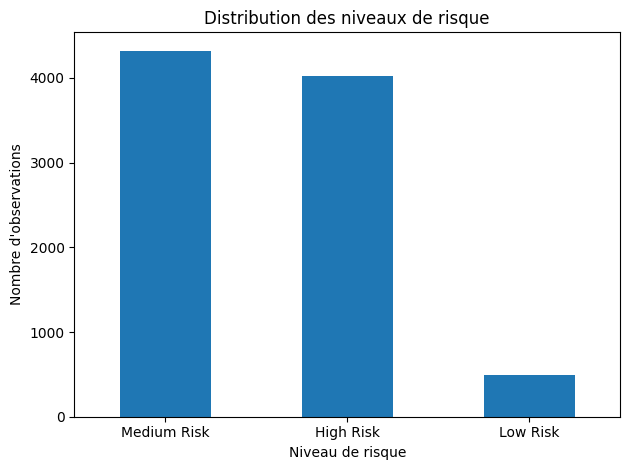

In [15]:
risk_labels = {
    0: "Low Risk",
    1: "Medium Risk",
    2: "High Risk"
}

df["risk_label"] = df["risk_level"].map(risk_labels)

df["risk_label"].value_counts().plot(kind="bar")

plt.title("Distribution des niveaux de risque")
plt.xlabel("Niveau de risque")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "target_distribution.png", dpi=300)
plt.show()

Cell 12 — Correlation matrix

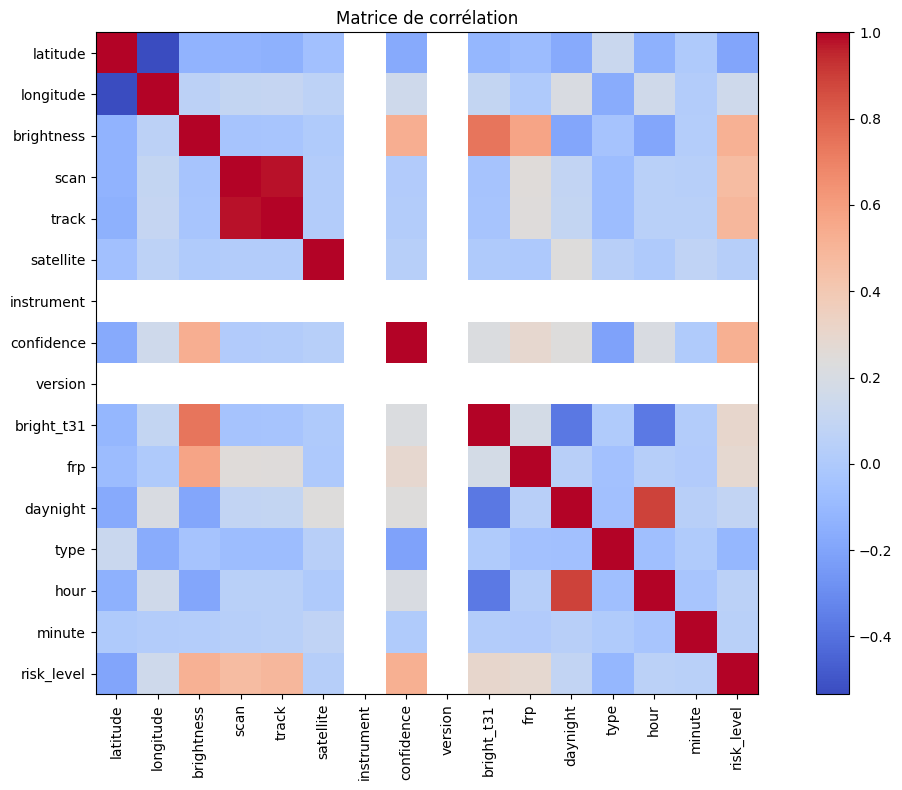

In [16]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "correlation_matrix.png", dpi=300)
plt.show()

Cell 13 — Features and target

In [17]:
features = [
    "latitude",
    "longitude",
    "brightness",
    "scan",
    "track",
    "satellite",
    "instrument",
    "confidence",
    "version",
    "bright_t31",
    "daynight",
    "type",
    "year",
    "month",
    "day",
    "hour",
    "minute"
]

X = df[features]
y = df["risk_level"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8834, 17)
y shape: (8834,)


Cell 14 — Train / validation / test split

In [18]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (6183, 17)
Validation: (1325, 17)
Test: (1326, 17)


Cell 15 — Scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, MODELS_DIR / "scaler.pkl")

print("Scaling completed.")

Scaling completed.


Cell 16 — Save processed data

In [20]:
np.save(PROCESSED_DIR / "X_train.npy", X_train_scaled)
np.save(PROCESSED_DIR / "X_val.npy", X_val_scaled)
np.save(PROCESSED_DIR / "X_test.npy", X_test_scaled)

np.save(PROCESSED_DIR / "y_train.npy", y_train.values)
np.save(PROCESSED_DIR / "y_val.npy", y_val.values)
np.save(PROCESSED_DIR / "y_test.npy", y_test.values)

print("Processed data saved successfully.")

Processed data saved successfully.


Cell 17 — Save feature names

In [21]:
with open(MODELS_DIR / "feature_names.json", "w") as f:
    json.dump(features, f)

print("Feature names saved.")

Feature names saved.


Cell 18 — Save cleaned CSV

In [22]:
df.to_csv(PROCESSED_DIR / "modis_cleaned.csv", index=False)

print("Cleaned dataset saved.")

Cleaned dataset saved.


Cell 19 — Final check

In [23]:
print("Preprocessing completed successfully.")
print("Created files:")
print("- models/scaler.pkl")
print("- models/encoder_satellite.pkl")
print("- models/encoder_instrument.pkl")
print("- models/encoder_daynight.pkl")
print("- models/feature_names.json")
print("- dataset/processed/X_train.npy")
print("- dataset/processed/X_val.npy")
print("- dataset/processed/X_test.npy")
print("- dataset/processed/y_train.npy")
print("- dataset/processed/y_val.npy")
print("- dataset/processed/y_test.npy")
print("- results/correlation_matrix.png")
print("- results/target_distribution.png")

Preprocessing completed successfully.
Created files:
- models/scaler.pkl
- models/encoder_satellite.pkl
- models/encoder_instrument.pkl
- models/encoder_daynight.pkl
- models/feature_names.json
- dataset/processed/X_train.npy
- dataset/processed/X_val.npy
- dataset/processed/X_test.npy
- dataset/processed/y_train.npy
- dataset/processed/y_val.npy
- dataset/processed/y_test.npy
- results/correlation_matrix.png
- results/target_distribution.png
